# 02 — Εντοπισμός κορυφών: σύγκριση μεθόδων

Βήμα 2 της εκφώνησης. Συγκρίνουμε τις δύο μεθόδους του `src/peaks.py` σε 8 όρους, πάνω στο **ποσοστό** άρθρων του μήνα (αναζήτηση σε τίτλο + κείμενο, όλοι οι τύποι της λέξης).

- **prominence**: τοπικά μέγιστα που ξεχωρίζουν από τους γύρω μήνες (`scipy.signal.find_peaks`).
- **z-score**: μήνες πολύ πάνω από τον μέσο όρο των προηγούμενων 12 μηνών (z ≥ 2).

Κοινά φίλτρα: ≥ 5 άρθρα, ≥ 8% της μέγιστης τιμής του όρου, ≥ 3 μήνες απόσταση μεταξύ κορυφών.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import peaks
from src.search import NewsIndex, make_query

idx = NewsIndex()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [2]:
TERMS = ['μνημόνιο', 'πανδημία', 'ακρίβεια', 'μεταναστευτικό', 'ΕΚΤ', 'σεισμός', 'Ουκρανία', 'Τραμπ']
series = {t: idx.monthly(make_query(t), 'text') for t in TERMS}
found = {(t, m): peaks.detect(series[t], m, n=6) for t in TERMS for m in peaks.METHODS}

## Γραφήματα: κόκκινο = prominence, πράσινο = z-score

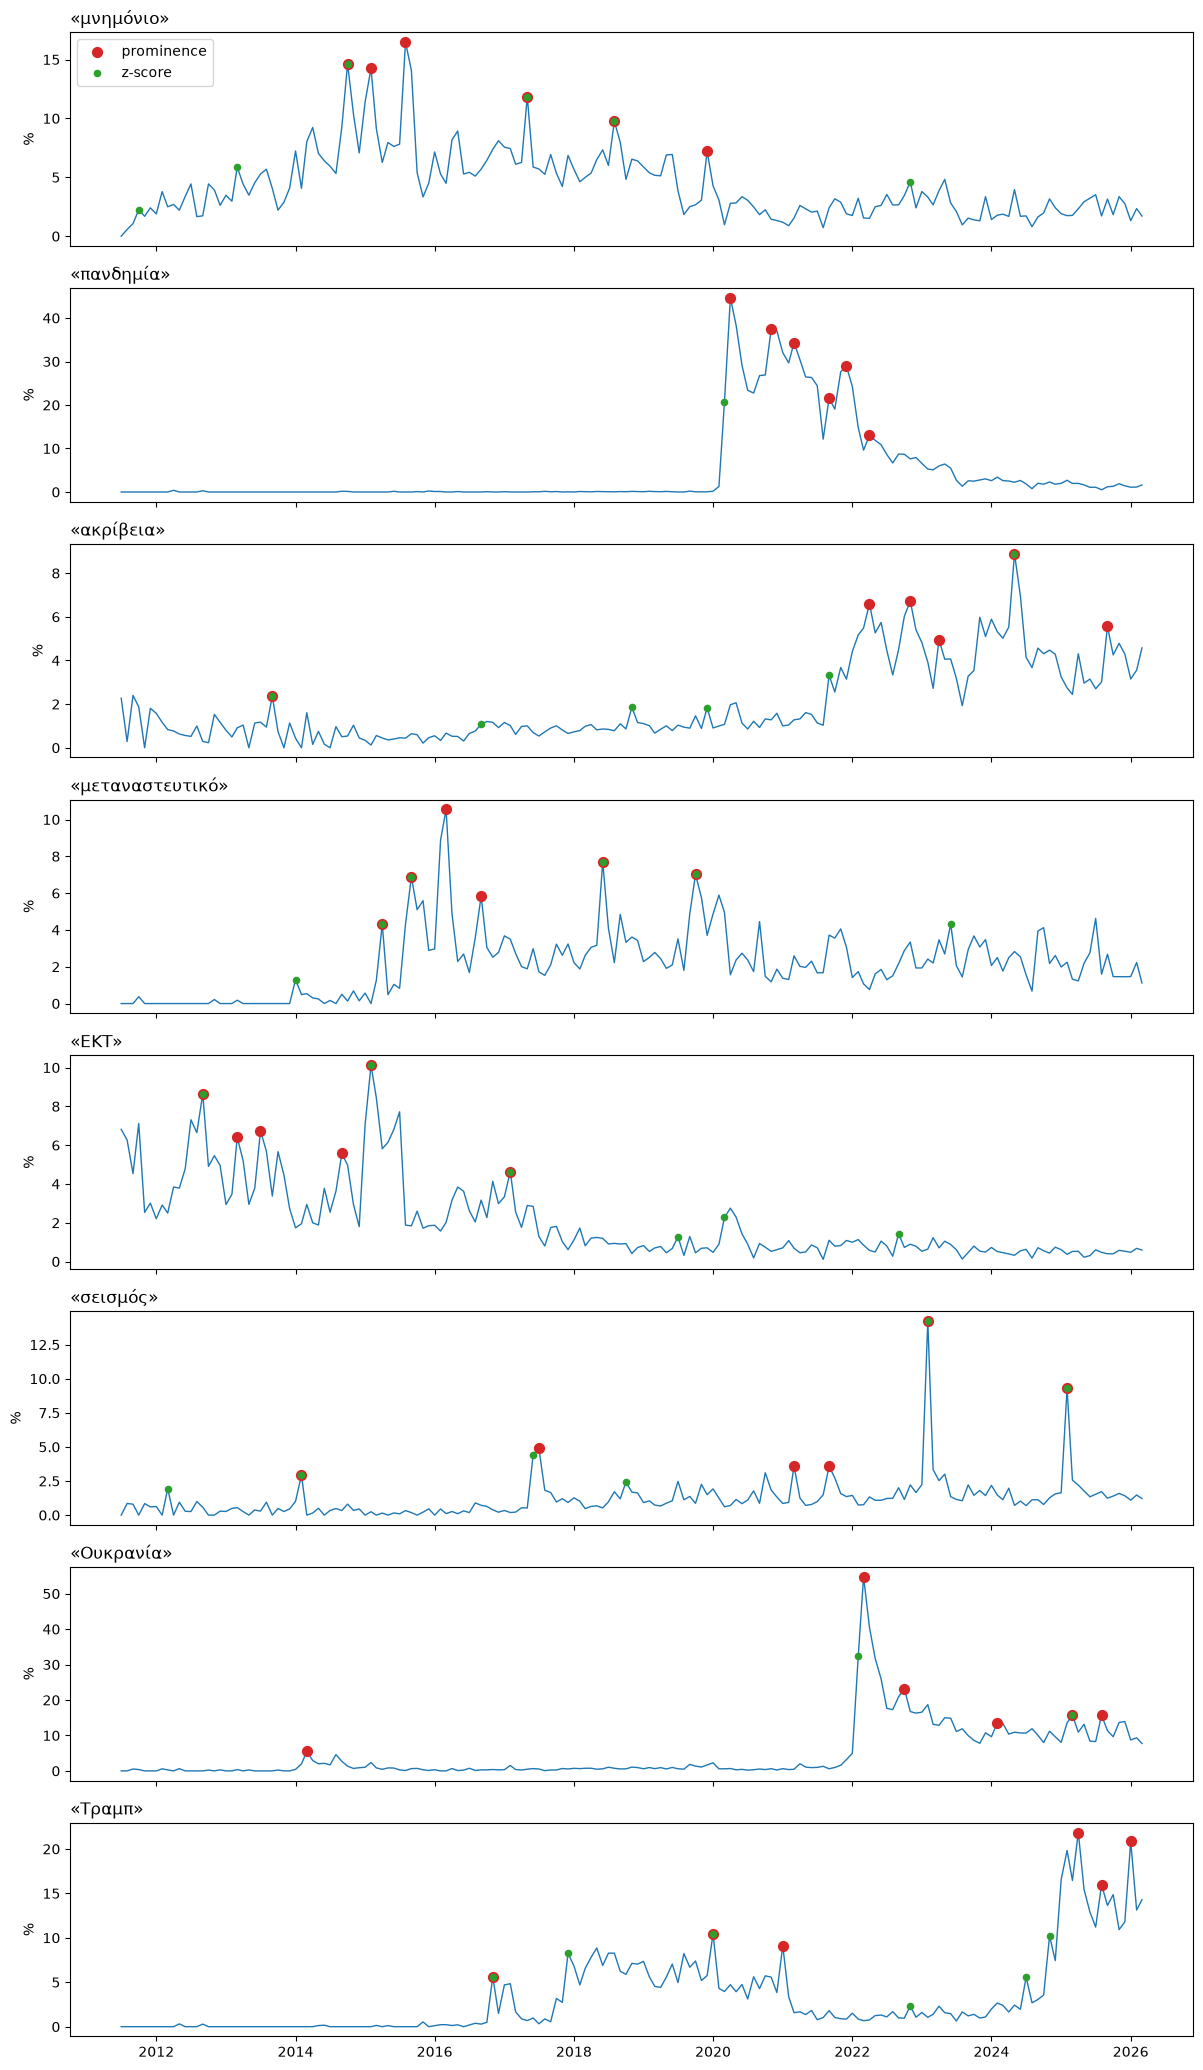

In [3]:
fig, axes = plt.subplots(len(TERMS), 1, figsize=(12, 2.6 * len(TERMS)), sharex=True)
for ax, t in zip(axes, TERMS):
    d = series[t]
    ax.plot(d.month, d.share, lw=1, color='#1f77b4')
    p, z = found[(t, 'prominence')], found[(t, 'zscore')]
    ax.scatter(p.month, p.share, color='#d62728', s=50, zorder=3, label='prominence')
    ax.scatter(z.month, z.share, color='#2ca02c', s=20, zorder=4, label='z-score')
    ax.set_title(f'«{t}»', loc='left'); ax.set_ylabel('%')
axes[0].legend(loc='upper left')
plt.tight_layout()

## Πίνακας κορυφών ανά μέθοδο

In [4]:
rows = []
for t in TERMS:
    for m in peaks.METHODS:
        p = found[(t, m)]
        rows.append({'όρος': t, 'μέθοδος': m,
                     'κορυφές (μήνας, %)': ', '.join(f'{r.month:%Y-%m} ({r.share:.1f})' for r in p.itertuples())})
pd.set_option('display.max_colwidth', None)
pd.DataFrame(rows)

,όρος,μέθοδος,"κορυφές (μήνας, %)"
0,μνημόνιο,prominence,"2014-10 (14.7), 2015-02 (14.2), 2015-08 (16.5), 2017-05 (11.8), 2018-08 (9.8), 2019-12 (7.2)"
1,μνημόνιο,zscore,"2011-10 (2.2), 2013-03 (5.9), 2014-10 (14.7), 2017-05 (11.8), 2018-08 (9.8), 2022-11 (4.6)"
2,πανδημία,prominence,"2020-04 (44.6), 2020-11 (37.4), 2021-03 (34.3), 2021-09 (21.6), 2021-12 (29.0), 2022-04 (13.0)"
3,πανδημία,zscore,2020-03 (20.8)
4,ακρίβεια,prominence,"2013-09 (2.4), 2022-04 (6.6), 2022-11 (6.7), 2023-04 (4.9), 2024-05 (8.9), 2025-09 (5.6)"
5,ακρίβεια,zscore,"2013-09 (2.4), 2016-09 (1.1), 2018-11 (1.9), 2019-12 (1.8), 2021-09 (3.3), 2024-05 (8.9)"
6,μεταναστευτικό,prominence,"2015-04 (4.3), 2015-09 (6.9), 2016-03 (10.5), 2016-09 (5.8), 2018-06 (7.7), 2019-10 (7.0)"
7,μεταναστευτικό,zscore,"2014-01 (1.3), 2015-04 (4.3), 2015-09 (6.9), 2018-06 (7.7), 2019-10 (7.0), 2023-06 (4.3)"
8,ΕΚΤ,prominence,"2012-09 (8.6), 2013-03 (6.4), 2013-07 (6.7), 2014-09 (5.6), 2015-02 (10.1), 2017-02 (4.6)"
9,ΕΚΤ,zscore,"2012-09 (8.6), 2015-02 (10.1), 2017-02 (4.6), 2019-07 (1.3), 2020-03 (2.3), 2022-09 (1.4)"


## Συμπεράσματα

- **prominence** εντοπίζει τις στιγμές με τη μεγαλύτερη κάλυψη, που αντιστοιχούν σε γνωστά γεγονότα: Ουκρανία 03/2014 (Κριμαία) και 03/2022 (εισβολή), σεισμός 02/2023 (Τουρκία–Συρία), μεταναστευτικό 03/2016, μνημόνιο 08/2015 (3ο μνημόνιο), πανδημία 04/2020 και τα επόμενα κύματα.
- **z-score** εντοπίζει καλύτερα την **έναρξη** ενός γεγονότος (πανδημία 03/2020, Ουκρανία 02/2022) και αλλαγές από χαμηλά επίπεδα (εκλογές ΗΠΑ 11/2016 και 11/2024 για «Τραμπ»). Όταν ο όρος μένει ψηλά για καιρό (πανδημία), βρίσκει μόνο την αρχή, γιατί ο κυλιόμενος μέσος όρος ανεβαίνει κι αυτός.
- Χωρίς το φίλτρο «≥ 8% του μεγίστου» το z-score έβγαζε θόρυβο (π.χ. «πανδημία» 0,2% το 2019).
- **Επιλογή:** προεπιλογή η μέθοδος **prominence**, γιατί απαντά καλύτερα στο ερώτημα της εφαρμογής («πότε μίλησαν περισσότερο για τον όρο;»). Το z-score μένει διαθέσιμο ως εναλλακτική στην εφαρμογή.
- Η ποιοτική αξιολόγηση σε δείγμα (κορυφή ↔ πραγματικό γεγονός) γίνεται στη Φάση 7.